In [3]:
import os
import numpy as np
import random
import matplotlib.pyplot as plt

In [4]:
def check_files(dirpath, filename):
    files = os.listdir(dirpath)
    if filename in files:
        return True
    else :
        return False

In [9]:
check_files('./', "neural_net")

True

In [11]:
os.mkdir('./test')

FileExistsError: [WinError 183] Impossible de créer un fichier déjà existant: './test'

In [4]:
import pickle
def writing(filepath, obj):
    file_obj = open(filepath, "wb")
    pickle.dump(obj, file_obj)

def reading(filepath):
    file_obj = open(filepath, "rb")
    obj = pickle.load(file_obj)
    return(obj)

def adding(filepath, obj, N):
    file_obj = reading(filepath)
    file_obj[N] = obj
    pickle.dump(file_obj, open(filepath, "wb"))
    return(file_obj)

In [8]:
writing('./test', {"v" : "1"})

In [9]:
reading('./test')

{'v': '1'}

In [10]:
adding('./test', {"test1" : "value1"}, 1)

{'v': '1', 1: {'test1': 'value1'}}

In [11]:
reading('./test')

{'v': '1', 1: {'test1': 'value1'}}

In [12]:
adding('./test', {"test2" : "value2"}, 2)

{'v': '1', 1: {'test1': 'value1'}, 2: {'test2': 'value2'}}

In [13]:
values = reading('./test')
print(values[1])

{'test1': 'value1'}


In [16]:
N_planes = 8
mesure_number = 1
N_planes = N_planes + 1 if mesure_number != 0 else 7
print(N_planes)

9


In [25]:
fx = liste_entiers = [random.randint(1, 10) for _ in range(20)]
fy = liste_entiers = [random.randint(1, 10) for _ in range(20)]

[2, 8, 4, 7, 1, 7, 3, 8, 6, 1, 1, 9, 10, 7, 1, 9, 9, 5, 5, 4] [2, 9, 4, 8, 1, 10, 4, 5, 10, 9, 6, 1, 6, 8, 10, 4, 3, 7, 2, 5]


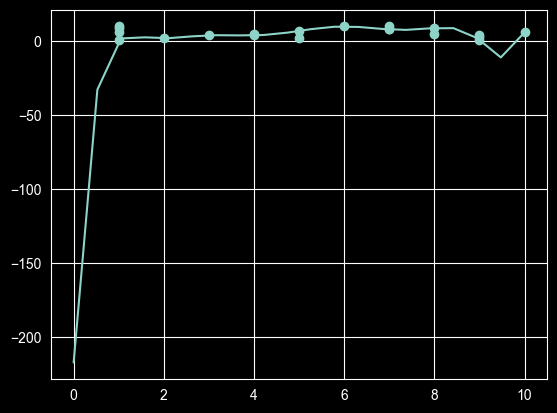

In [28]:
def getInterpolator(fx, fy, smooth, xstart, xend):
    def getLagrange(i, x):
        L = 1
        for j in range(len(fx)):
            if j != i:
                L*=(x-fx[j])/(fx[i]-fx[j])
        return L

    xs = [xstart + i*(xend-xstart)/(smooth-1) for i in range(smooth)]
    ys = []
    for x in xs:
        P = 0
        for j in range(len(fx)):
            P += fy[j]*getLagrange(j, x)
        ys.append(P)
    return xs, ys

print(fx, fy)
fx_n, fy_n = np.array(fx), np.array(fy)
fx_u, index_u = np.unique(fx_n, return_index=True)
fy_u = fy_n[index_u]
xs1, ys1 = getInterpolator(fx_u, fy_u, 20, 0, 10)
plt.plot(xs1, ys1)
plt.scatter(fx, fy)
plt.show()

[2, 8, 4, 7, 1, 7, 3, 8, 6, 1, 1, 9, 10, 7, 1, 9, 9, 5, 5, 4] [2, 9, 4, 8, 1, 10, 4, 5, 10, 9, 6, 1, 6, 8, 10, 4, 3, 7, 2, 5]


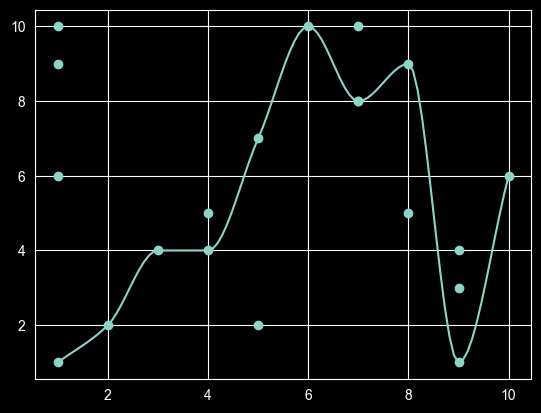

In [29]:
def getPCHIPInterpolator(fx, fy, smooth):
    n = len(fx)
    if n < 2:
        return fx, fy

    h = [fx[i+1] - fx[i] for i in range(n - 1)]         # x step list btw two points
    delta = [(fy[i+1] - fy[i]) / h[i] for i in range(n - 1)]    # slope list btw two points

    d = [0.0]*n
    # Fritsch-Carlson formula to keep monotony
    for i in range(1, n - 1):
        # Blocking oscillation if 2 adjacent slopes are opposite sign
        if delta[i-1] * delta[i] <= 0:
            d[i] = 0.0
        # weighted average favoring the least steep slope
        else:
            w1 = 2*h[i] + h[i-1]
            w2 = h[i] + 2*h[i-1]
            d[i] = (w1 + w2) / (w1/delta[i-1] + w2/delta[i])

    # Extremity slopes
    d[0] = delta[0] if (n > 1 and delta[0] != 0) else 0.0
    d[-1] = delta[-1] if (n > 1 and delta[-1] != 0) else 0.0

    # Interpolation coo
    step = (fx[-1] - fx[0]) / (smooth-1)
    xs = [fx[0] + i*step for i in range(smooth)]
    ys = []

    for x in xs:
        if x <= fx[0]:
            ys.append(fy[0])
            continue
        if x >= fx[-1]:
            ys.append(fy[-1])
            continue

        k = 0
        while k < n-2 and x > fx[k+1]:
            k += 1

        t = (x - fx[k])/h[k]
        h00 = 2*t**3 - 3*t**2 + 1
        h10 = t**3 - 2*t**2 + t
        h01 = -2*t**3 + 3*t**2
        h11 = t**3 - t**2

        ys.append(fy[k]*h00 + h[k]*d[k]*h10 + fy[k+1]*h01 + h[k]*d[k+1]*h11)

    return xs, ys

print(fx, fy)
plt.scatter(fx, fy)
fx_n, fy_n = np.array(fx), np.array(fy)
fx_u, index_u = np.unique(fx_n, return_index=True)
fy_u = fy_n[index_u]
xs2, ys2 = getPCHIPInterpolator(fx_u, fy_u, 100)
plt.plot(xs2, ys2)
plt.show()

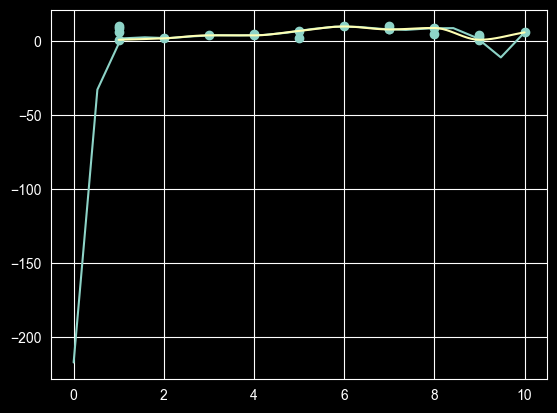

In [30]:
plt.plot(xs1, ys1)
plt.plot(xs2, ys2)
plt.scatter(fx, fy)
plt.show()